In [1]:
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt

import IPython

# Import IPython display for proper LaTeX formatting
from IPython.display import display, Math, Markdown

import sympy.physics.vector as spv
from sympy.physics.vector.printing import init_vprinting
# Initialize symbols
smp.init_printing()

# Enable dot notation printing for dynamicsymbols
init_vprinting(use_latex="mathjax")

PI = smp.S.Pi
HALF = smp.S.Half
INFINITY = smp.S.Infinity
NEG_INFINITY = smp.S.NegativeInfinity

# Introduction

Symbols can be defined as follows:

In [2]:
x = smp.symbols('x')

You can then use various mathematical operators on the defined symbols

In [3]:
x**2

 2
x 

In [4]:
smp.sin(x)

sin(x)

There are many many functions built into sympy

In [5]:
#smp.

Can save expressions in new variables

In [6]:
y = x**2 + 4*x + 3
y

 2          
x  + 4⋅x + 3

Do operations on the new variables:

In [7]:
z = y**2
z

              2
⎛ 2          ⎞ 
⎝x  + 4⋅x + 3⎠ 

Note that it doesn't expand. There are different methods you need to call to do different things with the expression:

In [8]:
z.factor()

       2        2
(x + 1) ⋅(x + 3) 

In the notation `smp.solve(f,x)`, sympy finds the value of $x$ that makes $f(x)=0$. 

In [9]:
smp.solve(z,x)

[-3, -1]

In [10]:
smp.solve(smp.sin(x), x)

[0, π]

**Good Practice**: If you know that your variable $x$ is real (and in some cases non-negative) it's good to specify this when you define your variables to prevent complicated issues when solving complicated problems (especially with integrals).

In [11]:
x = smp.symbols('x')
smp.solve(x**2+1, x)

[-ⅈ, ⅈ]

In [12]:
x = smp.symbols('x', real=True, positive=True)
smp.solve(x+4, x)

[]

Can define many variables at once

In [13]:
x, y, z = smp.symbols('x y z')
F = x**2+smp.sin(z)*y
F

 2           
x  + y⋅sin(z)

Can also solve multivariable expressions, specifying which variable we want to solve for. In each case, $F=0$ is being solved for

In [14]:
x_sols = smp.solve(F, x)
x_sols

⎡   ___________    ___________⎤
⎣-╲╱ -y⋅sin(z) , ╲╱ -y⋅sin(z) ⎦

In [15]:
y_sols = smp.solve(F,y)
y_sols

⎡   2  ⎤
⎢ -x   ⎥
⎢──────⎥
⎣sin(z)⎦

In [16]:
z_sols = smp.solve(F,z)
z_sols

⎡    ⎛ 2⎞           ⎛ 2⎞⎤
⎢    ⎜x ⎟           ⎜x ⎟⎥
⎢asin⎜──⎟ + π, -asin⎜──⎟⎥
⎣    ⎝y ⎠           ⎝y ⎠⎦

Finally, it may be the case that one has a sympy expression but wants to convert it into a numerical function so they can plot on a computer

In [17]:
expr = z_sols[0]
expr

    ⎛ 2⎞    
    ⎜x ⎟    
asin⎜──⎟ + π
    ⎝y ⎠    

In [18]:
expr_f = smp.lambdify([x,y], expr)
expr_f(1,2)

np.float64(3.6651914291880923)

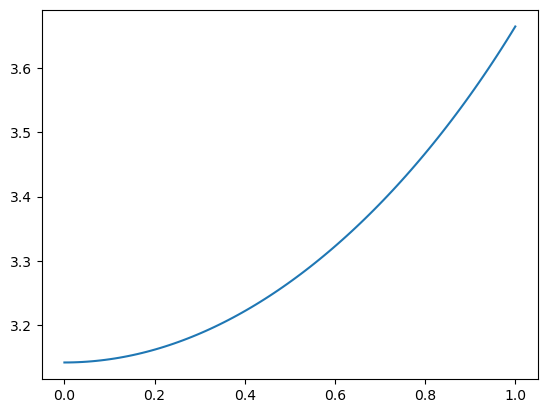

In [19]:
x_num = np.linspace(0,1,100)
y_num = 2
plt.plot(x_num, expr_f(x_num,y_num))
plt.show()

For multivariable expressions, can also substitute values in

In [20]:
F

 2           
x  + y⋅sin(z)

In [21]:
F.subs([(y,smp.cos(z)),(z,y)])

 2                
x  + sin(y)⋅cos(y)

# Examples

A falling object encounters a moving platform accelerating upwards:

1. Object $h_o(t) = h_0 - v_o t - \frac{1}{2}gt^2$
2. Platform $h_p(t) = v_p t + \frac{1}{2}qt^2$

**Find the initial velocity $v_0$ such that when the object and platform collide, they are moving at the same speed.**

We need to solve for $v_0$ and $t$ in the two equations

1. $h_0(t) = h_p(t)$
2. $ \frac{dh_0}{dt} (t) = - \frac{dh_p}{dt}(t) $

In sympy, need to construct our system of equations as $EQ_1=0$, $EQ_2=0$, ... In our case, we rewrite them as

1. $h_0(t) - h_p(t) = 0$
2. $\frac{dh_0}{dt} + \frac{dh_p}{dt} = 0$

In [22]:
t, h0, v0, g, vp, q = smp.symbols('t h_0 v_0 g v_p q', real=True, positive=True)

Define expressions

In [23]:
h0t = h0 - v0*t - smp.Rational(1,2)*g*t**2
dh0dt = g*t - v0
hpt = vp*t + smp.Rational(1,2)*q*t**2
dhpdt = vp + q*t

Define equations

In [24]:
eq1 = h0t - hpt
eq2 = dh0dt + dhpdt

Solve the equations

In [25]:
smp.solve([eq1, eq2], [t, v0])[0]

⎛               _________________________                                      ⎞
⎜              ╱                       2                                       ⎟
⎜  2⋅vₚ   √2⋅╲╱  3⋅g⋅h₀ + 3⋅h₀⋅q + 2⋅vₚ               _________________________⎟
⎜- ──── + ───────────────────────────────            ╱                       2 ⎟
⎜   3                    3                 vₚ   √2⋅╲╱  3⋅g⋅h₀ + 3⋅h₀⋅q + 2⋅vₚ  ⎟
⎜────────────────────────────────────────, ── + ───────────────────────────────⎟
⎝                 g + q                    3                   3               ⎠

In [26]:
t_collide, v_initfall = smp.solve([eq1, eq2], [t, v0])[0]

In [27]:
v_initfall

           _________________________
          ╱                       2 
vₚ   √2⋅╲╱  3⋅g⋅h₀ + 3⋅h₀⋅q + 2⋅vₚ  
── + ───────────────────────────────
3                   3               

In [28]:
t_collide

               _________________________
              ╱                       2 
  2⋅vₚ   √2⋅╲╱  3⋅g⋅h₀ + 3⋅h₀⋅q + 2⋅vₚ  
- ──── + ───────────────────────────────
   3                    3               
────────────────────────────────────────
                 g + q                  

**What is the velocity when they collide?**

In [29]:
dh0dt.subs([(t,t_collide),(v0,v_initfall)]).simplify()

                    _________________________
                   ╱                       2 
        q⋅vₚ   q⋅╲╱  6⋅g⋅h₀ + 6⋅h₀⋅q + 4⋅vₚ  
-g⋅vₚ - ──── - ──────────────────────────────
         3                   3               
─────────────────────────────────────────────
                    g + q                    

In [30]:
dhpdt.subs([(t,t_collide),(v0,v_initfall)]).simplify()

                   _________________________
                  ╱                       2 
       q⋅vₚ   q⋅╲╱  6⋅g⋅h₀ + 6⋅h₀⋅q + 4⋅vₚ  
g⋅vₚ + ──── + ──────────────────────────────
        3                   3               
────────────────────────────────────────────
                   g + q                    

# Calculus (1st year)

Watch my video here for a more in depth discussion: https://www.youtube.com/watch?v=-SdIZHPuW9o

In [31]:
x = smp.symbols('x')

## Limits

$$\lim_{x \to \pi} \sin(x/2+ \sin(x))$$

In [32]:
smp.limit(smp.sin(x/2 + smp.sin(x)), x, smp.pi)

1

## Derivatives

$$ \frac{d}{dx} \left( \frac{1+\sin x}{1 - \cos x} \right)^2 $$

In [33]:
smp.diff(((1 + smp.sin(x)) / (1 - smp.cos(x)))**2, x)

                                      2       
2⋅(sin(x) + 1)⋅cos(x)   2⋅(sin(x) + 1) ⋅sin(x)
───────────────────── - ──────────────────────
                2                       3     
    (1 - cos(x))            (1 - cos(x))      

$$\frac{d}{dx} f(x+g(x)) $$

In [34]:
f, g = smp.symbols('f g', cls=smp.Function)

In [35]:
f, g = smp.symbols('f g', cls=smp.Function)
g = g(x)
f = f(x+g)

In [36]:
f

f(x + g(x))

In [37]:
dfdx = smp.diff(f,x)
dfdx

⎛d           ⎞ ⎛ d        ⎞│           
⎜──(g(x)) + 1⎟⋅⎜───(f(ξ₁))⎟│           
⎝dx          ⎠ ⎝dξ₁       ⎠│ξ₁=x + g(x)

In [38]:
dfdx.subs([(g, smp.sin(x))]).doit() # need to call doit

             ⎛ d        ⎞│             
(cos(x) + 1)⋅⎜───(f(ξ₁))⎟│             
             ⎝dξ₁       ⎠│ξ₁=x + sin(x)

## Basic Antiderivatives

$$ \int \csc(x) \cot (x)  dx $$

In [39]:
smp.integrate(smp.csc(x)*smp.cot(x), x)

 -1   
──────
sin(x)

## Definite Integrals

$$\int_{0}^{\ln(4)}\frac{e^x dt}{\sqrt{e^{2x}+9}} $$

In [40]:
smp.integrate(smp.exp(x) / smp.sqrt(smp.exp(2*x) + 9), (x, 0, smp.log(4)))

-asinh(1/3) + asinh(4/3)

$$\int_1^t x^{10} e^x dx $$

In [41]:
t= smp.symbols('t')

In [42]:
smp.integrate(x**10*smp.exp(x), (x, 1, t))

⎛ 10       9       8        7         6          5           4           3     ↪
⎝t   - 10⋅t  + 90⋅t  - 720⋅t  + 5040⋅t  - 30240⋅t  + 151200⋅t  - 604800⋅t  + 1 ↪

↪         2                      ⎞  t            
↪ 814400⋅t  - 3628800⋅t + 3628800⎠⋅ℯ  - 1334961⋅ℯ

# Examples

The hydrogen wave function is given by

$$\psi_{nlm} = R_{nl}(r)Y_l^m(\theta, \phi) $$

$$R_{nl}(r) =  \sqrt{\left(\frac{2}{na}\right)^3 \frac{(n-l-1)!}{2n[(n+1)!]}} e^{-r/na} \left(\frac{2r}{na}\right)^l \left[L_{n-l-1}^{2l+1}(2r/na)\right]$$

The mean distance from the nucleus of the electron:

$$\left<r\right> = \int R_{nl}^2 r^3 dr$$

The standard deviation in the distance from the nucleus of the electron:

$$\sigma = \sqrt{\left<r^2\right> - \left<r\right>^2} =  \sqrt{\left(\int_{0}^{\infty}R_{nl}^2 r^4 dr\right) - \left(\int_{0}^{\infty} R_{nl}^2 r^3 dr\right)^2}$$

In [43]:
from sympy import assoc_laguerre

Define variables, be sure to specify their attributes

In [44]:
r, a = smp.symbols('r a', real=True, positive=True)
n, l = smp.symbols('n l', integer=True, positive=True)

Define $R_{nl}(r)$

In [45]:
R = smp.sqrt((2/(n*a))**3 * smp.factorial(n-l-1)/(2*n*(smp.factorial(n+l)))) \
     *smp.exp(-r/(n*a)) * (2*r/(n*a))**l * assoc_laguerre(n-l-1,2*l+1,(2*r/(n*a)))
R

          -r                                                            
       l  ───                                                           
  ⎛2⋅r⎞   a⋅n               ⎛                     2⋅r⎞   _______________
2⋅⎜───⎟ ⋅ℯ   ⋅assoc_laguerre⎜-l + n - 1, 2⋅l + 1, ───⎟⋅╲╱ (-l + n - 1)! 
  ⎝a⋅n⎠                     ⎝                     a⋅n⎠                  
────────────────────────────────────────────────────────────────────────
                           3/2  2   __________                          
                          a   ⋅n ⋅╲╱ (l + n)!                           

We can check to make sure this corresponds to the radial wavefunctions we expect. Lets see $R_{10}(r)$

In [46]:
R_10 = R.subs([(n,4),(l,3)])
R_10

        -r 
        ───
     3  4⋅a
√35⋅r ⋅ℯ   
───────────
       9/2 
26880⋅a    

Function to compute $\int_{0}^{\infty} R_{nl}^2 r^k dr$ for particular values of $n$, $l$ and $k$

In [47]:
def compute_int(n_val, l_val, k):
    R_nl = R.subs([(n,n_val),(l,l_val)])
    return smp.integrate(R_nl**2 * r**k, (r,0,smp.oo))

Compute the mean radial distance of an electron in the state $\psi_{100}$

In [48]:
compute_int(n_val=3,l_val=1,k=3)

25⋅a
────
 2  

Compute the spread $\sigma$ in distances of the electron in state $\psi_{100}$

In [49]:
smp.sqrt(compute_int(n_val=1,l_val=0,k=4) - compute_int(n_val=1,l_val=0,k=3)**2)

√3⋅a
────
 2  

Compute the mean radial distance of an electron in the state $\psi_{420}$

In [50]:
compute_int(n_val=4,l_val=2,k=3)

21⋅a

In [51]:
def compute_mean_distance(n_val, l_val=0):
    expr = compute_int(n_val,l_val,k=3)
    expr_f = smp.lambdify([a], expr)
    return expr_f(1)

In [52]:
ns = np.arange(1,10)
ds =[compute_mean_distance(ni) for ni in ns]

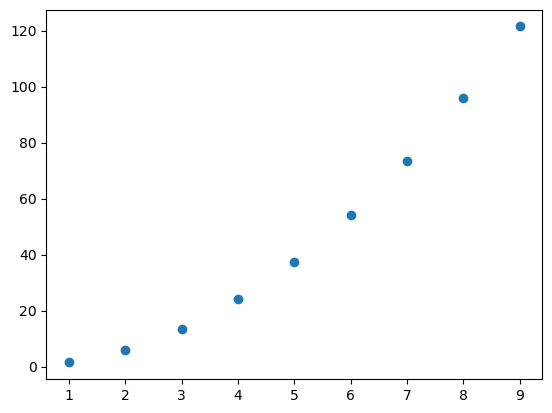

In [53]:
plt.scatter(ns, ds)

# Multivariable Calculus

In [54]:
x, y, z, u1, u2, u3, v1, v2, v3, t = smp.symbols('x y z u_1 u_2 u_3 v_1 v_2 v_3 t')

## Vectors and Geometry

In [55]:
u = smp.Matrix([u1,u2,u3])
v = smp.Matrix([v1,v2,v3])

### Addition and multiplication

In [56]:
2*u+v

⎡2⋅u₁ + v₁⎤
⎢         ⎥
⎢2⋅u₂ + v₂⎥
⎢         ⎥
⎣2⋅u₃ + v₃⎦

Dot product

In [57]:
u.dot(v)

u₁⋅v₁ + u₂⋅v₂ + u₃⋅v₃

Cross product

In [58]:
u.cross(v)

⎡u₂⋅v₃ - u₃⋅v₂ ⎤
⎢              ⎥
⎢-u₁⋅v₃ + u₃⋅v₁⎥
⎢              ⎥
⎣u₁⋅v₂ - u₂⋅v₁ ⎦

Norm

In [59]:
u.norm()

   _______________________
  ╱     2       2       2 
╲╱  │u₁│  + │u₂│  + │u₃│  

$\text{proj}_v(u) = \frac{u \cdot v}{|v|^2} v$

In [60]:
proj_v_u = u.dot(v)/v.norm()**2 * v
proj_v_u

⎡v₁⋅(u₁⋅v₁ + u₂⋅v₂ + u₃⋅v₃)⎤
⎢──────────────────────────⎥
⎢      2       2       2   ⎥
⎢  │v₁│  + │v₂│  + │v₃│    ⎥
⎢                          ⎥
⎢v₂⋅(u₁⋅v₁ + u₂⋅v₂ + u₃⋅v₃)⎥
⎢──────────────────────────⎥
⎢      2       2       2   ⎥
⎢  │v₁│  + │v₂│  + │v₃│    ⎥
⎢                          ⎥
⎢v₃⋅(u₁⋅v₁ + u₂⋅v₂ + u₃⋅v₃)⎥
⎢──────────────────────────⎥
⎢      2       2       2   ⎥
⎣  │v₁│  + │v₂│  + │v₃│    ⎦

Lines: $\vec{r}(t) = \vec{r}_0 + t\vec{v}$

In [61]:
r0 = smp.Matrix([1,1,1])
v = smp.Matrix([1,3,-1])
r = r0 + t*v
r

⎡ t + 1 ⎤
⎢       ⎥
⎢3⋅t + 1⎥
⎢       ⎥
⎣ 1 - t ⎦

Planes: $\vec{n} \cdot (P_0-\left<x,y,z\right>) = 0$

In [62]:
P0 = smp.Matrix([4,4,8])
r = smp.Matrix([x,y,z])
n = smp.Matrix([1,1,1])
n.dot(P0-r)

-x - y - z + 16

## Vector Calculus

### Vector Derivatives

In [63]:
r = smp.Matrix([3*t, smp.sin(t), t**2])
r

⎡ 3⋅t  ⎤
⎢      ⎥
⎢sin(t)⎥
⎢      ⎥
⎢   2  ⎥
⎣  t   ⎦

In [64]:
smp.diff(r,t)

⎡  3   ⎤
⎢      ⎥
⎢cos(t)⎥
⎢      ⎥
⎣ 2⋅t  ⎦

**Example:** Find the angle between the velocity and acceleration as a function of time $\theta(t)$

In [65]:
v = smp.diff(r,t)
a = smp.diff(v,t)
theta = smp.acos(v.dot(a)/(v.norm()*a.norm())).simplify()
theta

    ⎛                      sin(2⋅t)                ⎞
    ⎜                4⋅t - ────────                ⎟
    ⎜                         2                    ⎟
acos⎜──────────────────────────────────────────────⎟
    ⎜   _______________    ________________________⎟
    ⎜  ╱         2        ╱      2           2     ⎟
    ⎝╲╱  │sin(t)│  + 4 ⋅╲╱  4⋅│t│  + │cos(t)│  + 9 ⎠

Find theta at $t=6$

In [66]:
theta.subs(t,6).evalf()

0.251108015692338

### Vector Integrals

(Note: Will not add the +C)

In [67]:
r = smp.Matrix([smp.exp(t)*smp.cos(t), t**4, 1/(1+t**2)])
r

⎡ t       ⎤
⎢ℯ ⋅cos(t)⎥
⎢         ⎥
⎢    4    ⎥
⎢   t     ⎥
⎢         ⎥
⎢   1     ⎥
⎢ ──────  ⎥
⎢  2      ⎥
⎣ t  + 1  ⎦

In [68]:
smp.Integral(r,t).doit()

⎡ t           t       ⎤
⎢ℯ ⋅sin(t)   ℯ ⋅cos(t)⎥
⎢───────── + ─────────⎥
⎢    2           2    ⎥
⎢                     ⎥
⎢          5          ⎥
⎢         t           ⎥
⎢         ──          ⎥
⎢         5           ⎥
⎢                     ⎥
⎣       atan(t)       ⎦

Some cases integrals can't be solved analytically - > see Second Year in Calculus video

In [69]:
from scipy.integrate import quad_vec

In [70]:
r = smp.Matrix([smp.exp(t**2)*smp.cos(t)**3, smp.exp(-t**4), 1/(3+t**2)])
r

⎡ ⎛ 2⎞        ⎤
⎢ ⎝t ⎠    3   ⎥
⎢ℯ    ⋅cos (t)⎥
⎢             ⎥
⎢       4     ⎥
⎢     -t      ⎥
⎢    ℯ        ⎥
⎢             ⎥
⎢     1       ⎥
⎢   ──────    ⎥
⎢    2        ⎥
⎣   t  + 3    ⎦

In [71]:
r_f = smp.lambdify([t], r)

In [72]:
from scipy.integrate import quad_vec
r = smp.Matrix([smp.exp(t**2)*smp.cos(t)**3, smp.exp(-t**4), 1/(3+t**2)])
r_f = smp.lambdify([t], r)
quad_vec(r_f, 0, 1)[0]

array([[0.81549671],
       [0.84483859],
       [0.30229989]])

### Arclength

$$L = \int_a^b \sqrt{dx^2 + dy^2 + dz^2} = \int_a^b \sqrt{(dx/dt)^2 + (dy/dt)^2 + (dz/dt)^2 } dt $$

Rare Cases can be done symbolically. Find arclength of $\left< 0, t, t^2 \right>$ from $t=0$ to $t=1$

In [73]:
r = smp.Matrix([0, t, t**2])
r

⎡0 ⎤
⎢  ⎥
⎢t ⎥
⎢  ⎥
⎢ 2⎥
⎣t ⎦

In [74]:
r = smp.Matrix([0, t, t**2])
smp.integrate(smp.diff(r,t).norm(), (t,0,1))

asinh(2)   √5
──────── + ──
   4       2 

# Examples

The magnetic field at a point $\vec{r}$ of a current configuration is 

$$\vec{B}(\vec{r}) = \frac{\mu_0}{4\pi}\int_t \frac{I \frac{d\vec{\ell}}{dt} \times (\vec{r}-\vec{\ell})}{|\vec{r}-\vec{\ell}|^3} dt $$

where $\vec{r} = (x,y,z)$ and $\vec{l} = (f(t), g(t), h(t))$ is a 1D curve in space that gives the location of the wire.

**Part 1: Use Sympy to find the integrand as a single 3-vector**

In [75]:
x, y, z, t, I, mu0 = smp.symbols('x y z t I \mu_0', real=True)
f, g, h = smp.symbols('f g h', cls=smp.Function)
f=f(t)
g=g(t)
h=h(t)

<>:1: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:1: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\jjmre\AppData\Local\Temp\ipykernel_7124\4026568624.py:1: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  x, y, z, t, I, mu0 = smp.symbols('x y z t I \mu_0', real=True)


Define $\vec{r}$, $\vec{\ell}$ and $\vec{d\ell/dt}$

In [76]:
r = smp.Matrix([x,y,z])
l = smp.Matrix([f,g,h])
dldt = smp.diff(l)

Define integrand

In [77]:
dBdt = I * dldt.cross(r-l) / (r-l).norm()**3

In [78]:
dBdt

⎡  ⎛             d                     d       ⎞⎤
⎢I⋅⎜- (y - g(t))⋅──(h(t)) + (z - h(t))⋅──(g(t))⎟⎥
⎢  ⎝             dt                    dt      ⎠⎥
⎢───────────────────────────────────────────────⎥
⎢                                          3/2  ⎥
⎢ ⎛          2             2             2⎞     ⎥
⎢ ⎝│x - f(t)│  + │y - g(t)│  + │z - h(t)│ ⎠     ⎥
⎢                                               ⎥
⎢   ⎛           d                     d       ⎞ ⎥
⎢ I⋅⎜(x - f(t))⋅──(h(t)) - (z - h(t))⋅──(f(t))⎟ ⎥
⎢   ⎝           dt                    dt      ⎠ ⎥
⎢ ───────────────────────────────────────────── ⎥
⎢                                          3/2  ⎥
⎢ ⎛          2             2             2⎞     ⎥
⎢ ⎝│x - f(t)│  + │y - g(t)│  + │z - h(t)│ ⎠     ⎥
⎢                                               ⎥
⎢  ⎛             d                     d       ⎞⎥
⎢I⋅⎜- (x - f(t))⋅──(g(t)) + (y - g(t))⋅──(f(t))⎟⎥
⎢  ⎝             dt                    dt      ⎠⎥
⎢───────────────────────────────────────────────⎥


**Part 2**: Find the magnetic field a distance $H$ above a ring of radius $R$ flowing clockwise

In [79]:
R, H = smp.symbols('R, H', real=True)

In [80]:
dBdt = dBdt.subs([(f, R*smp.cos(t)),
                  (g, R*smp.sin(t)),
                  (h, 0),
                  (x,0), (y,0), (z,H)]).doit()
dBdt.simplify()
dBdt

⎡H⋅I⋅R⋅cos(t)⎤
⎢────────────⎥
⎢         3/2⎥
⎢⎛ 2    2⎞   ⎥
⎢⎝H  + R ⎠   ⎥
⎢            ⎥
⎢H⋅I⋅R⋅sin(t)⎥
⎢────────────⎥
⎢         3/2⎥
⎢⎛ 2    2⎞   ⎥
⎢⎝H  + R ⎠   ⎥
⎢            ⎥
⎢       2    ⎥
⎢    I⋅R     ⎥
⎢────────────⎥
⎢         3/2⎥
⎢⎛ 2    2⎞   ⎥
⎣⎝H  + R ⎠   ⎦

Find magnetic field

In [81]:
mu0/(4*smp.pi) * smp.integrate(dBdt, [t,0,2*smp.pi])

⎡      0       ⎤
⎢              ⎥
⎢      0       ⎥
⎢              ⎥
⎢     2        ⎥
⎢  I⋅R ⋅\mu₀   ⎥
⎢──────────────⎥
⎢           3/2⎥
⎢  ⎛ 2    2⎞   ⎥
⎣2⋅⎝H  + R ⎠   ⎦

For more ccomplicated electrical wire configurations, see my video on solving for the magnetic field of an arbtriary wire (uses numerical integration)

## Partial/Directional Derivatives

In [82]:
x, y, z = smp.symbols('x y z')

### Basics

Partial Derivatives $\partial f / \partial x$ and $\partial f / \partial y$ of $f(x,y)=y^2\sin(x+y)$

In [83]:
f = y**2 * smp.sin(x+y)
smp.diff(f,x)

 2           
y ⋅cos(x + y)

In [84]:
smp.diff(f,y)

 2                            
y ⋅cos(x + y) + 2⋅y⋅sin(x + y)

Or more complicated things like $\frac{\partial^3 f}{\partial xy^2}$

In [85]:
smp.diff(f,y,y,x)

   2                                           
- y ⋅cos(x + y) - 4⋅y⋅sin(x + y) + 2⋅cos(x + y)

### The Chain Rule

In [86]:
t = smp.symbols('t')
x, y, z, w, v =smp.symbols('x, y, z w v', cls=smp.Function)

* Suppose $x$, $y$, and $z$ are functions of $t$ 
* $w$ is a function of $x$, $y$, and $z$. i.e $w=w(x,y,z)$

Find $dw/dt$

In [87]:
x = x(t)
y = y(t)
z = z(t)
w = w(x, y, z)

In [88]:
w

w(x, y, z)

Can keep things in a more functional form:

In [89]:
smp.diff(w,t)

d                  d                  d               
──(w(x, y, z))⋅ẋ + ──(w(x, y, z))⋅ẏ + ──(w(x, y, z))⋅ż
dx                 dy                 dz              

Or put in specific functions:

In [90]:
w1 = x**2+smp.exp(y)*smp.sin(z)

In [91]:
smp.diff(w1,t)

         y             y         
2⋅x⋅ẋ + ℯ ⋅sin(z)⋅ẏ + ℯ ⋅cos(z)⋅ż

In [92]:
w1 = x**2+smp.exp(y)*smp.sin(z)
smp.diff(w1,t).subs([(x, smp.sin(t)),
                    (y, smp.cos(t)),
                    (z, t**2)]).doit()

     cos(t)    ⎛ 2⎞    cos(t)           ⎛ 2⎞                  
2⋅t⋅ℯ      ⋅cos⎝t ⎠ - ℯ      ⋅sin(t)⋅sin⎝t ⎠ + 2⋅sin(t)⋅cos(t)

## Multiple Integrals

In rare cases these can be done symbolically:

$$\int_0^1 \int_0^{1-x^2} \int_3^{4-x^2-y^2} xdzdydx$$

In [93]:
x, y, z = smp.symbols('x, y, z')
f = x
smp.integrate(f, (z, 3, 4-x**2-y**2), (y, 0, 1-x**2), (x, 0, 1))

1/8

## Lagrangian Mechanics

The (simplified) idea of Lagrangian mechanics is the that kinetic energy and potential energy of a system can be expressed in terms of generalized coordinates and velocity

$$T = T(q,\dot{q}) \hspace{20mm} V=V(q,\dot{q})$$

where $q$ could be xyz of a point particle, or some angle $\theta$ (pendulum), or whatever makes the problem easiest to solve. The defining $L=T-V$, the following equation gives the equations of motion $q(t)$

$$\frac{dL}{dq} - \frac{d}{dt}\frac{dL}{d\dot{q}} = 0 $$

for all the different $q$'s of the system. The equation above gives a second order differential equation for all the different $q(t)$s.

**Example**: Find the equations of motion (in the form of differential equations)

<p align="center">
  <img src="..\images\symp_tut_p1.PNG" alt="drawing" width="300" align="center"/>
</p>

Let $(x,y)$ be the position of the pendulum bob

In [94]:
t, R, g, m1, m2 = smp.symbols('t R g m_1 m_2')
z, theta = smp.symbols(r'z \theta', cls=smp.Function)
z = z(t)
theta = theta(t)

dzdt = smp.diff(z,t)
dthedt = smp.diff(theta,t)

Define location of pendulum

In [95]:
x = z + R*smp.sin(theta)
y = -R*smp.cos(theta)

In [96]:
y

-R⋅cos(\theta)

Kinetic and potential energies

In [97]:
T1 = smp.Rational(1,2) * m1 * smp.diff(z,t)**2
T2 = smp.Rational(1,2) * m2 * (smp.diff(x,t)**2 + smp.diff(y,t)**2)
T = T1 + T2
V1 = 0
V2 = m2*g*y
V = V1 + V2

Get Lagrangian

In [98]:
L = T-V

In [99]:
L

                         2      ⎛ 2    2               2                       ↪
                     m₁⋅ż    m₂⋅⎝R ⋅sin (\theta)⋅\thėta  + (R⋅cos(\theta)⋅\thė ↪
R⋅g⋅m₂⋅cos(\theta) + ───── + ───────────────────────────────────────────────── ↪
                       2                                 2                     ↪

↪        2⎞
↪ ta + ż) ⎠
↪ ─────────
↪          

Get Lagranges equations of motion

In [100]:
LE1 = smp.diff(L, z) - smp.diff(smp.diff(L,dzdt), t)
LE2 = smp.diff(L, theta) - smp.diff(smp.diff(L,dthedt), t)

In [101]:
LE1

           ⎛                        2                               ⎞
        m₂⋅⎝- 2⋅R⋅sin(\theta)⋅\thėta  + 2⋅R⋅cos(\theta)⋅\thëta + 2⋅z̈⎠
-m₁⋅z̈ - ─────────────────────────────────────────────────────────────
                                      2                              

In [102]:
LE2

                         ⎛   2                               2                 ↪
                      m₂⋅⎝2⋅R ⋅sin(\theta)⋅cos(\theta)⋅\thėta  - 2⋅R⋅(R⋅cos(\t ↪
-R⋅g⋅m₂⋅sin(\theta) + ──────────────────────────────────────────────────────── ↪
                                                                    2          ↪

↪                                     ⎞      ⎛   2    2                     2  ↪
↪ heta)⋅\thėta + ż)⋅sin(\theta)⋅\thėta⎠   m₂⋅⎝2⋅R ⋅sin (\theta)⋅\thëta + 4⋅R ⋅ ↪
↪ ───────────────────────────────────── - ──────────────────────────────────── ↪
↪                                                                              ↪

↪                               2                                              ↪
↪ sin(\theta)⋅cos(\theta)⋅\thėta  - 2⋅R⋅(R⋅cos(\theta)⋅\thėta + ż)⋅sin(\theta) ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                                                            2                 ↪

↪               ⎛

We want a system of two second order differential equations that we can solve

In [103]:
sols = smp.solve([LE1, LE2], [smp.diff(z,t,t), smp.diff(theta,t,t)])

In [104]:
sols

⎧                                                       2                      ↪
⎪                    R⋅m₂⋅sin(\theta)⋅cos(\theta)⋅\thėta                       ↪
⎨\thëta: - ───────────────────────────────────────────────────────── - ─────── ↪
⎪                  2                   2                   2                   ↪
⎩          R⋅m₁⋅sin (\theta) + R⋅m₁⋅cos (\theta) + R⋅m₂⋅sin (\theta)   R⋅m₁⋅si ↪

↪                                                                              ↪
↪              g⋅m₁⋅sin(\theta)                                            g⋅m ↪
↪ ────────────────────────────────────────────────── - ─────────────────────── ↪
↪  2                   2                   2                   2               ↪
↪ n (\theta) + R⋅m₁⋅cos (\theta) + R⋅m₂⋅sin (\theta)   R⋅m₁⋅sin (\theta) + R⋅m ↪

↪                                                             3                ↪
↪ ₂⋅sin(\theta)                                       R⋅m₂⋅sin (\theta)⋅\thėta ↪
↪ ─────────────────────

Find $d^2 \theta / dt^2 = $

In [105]:
sols[smp.diff(theta,t,t)]

                                               2                               ↪
            R⋅m₂⋅sin(\theta)⋅cos(\theta)⋅\thėta                                ↪
- ───────────────────────────────────────────────────────── - ──────────────── ↪
          2                   2                   2                   2        ↪
  R⋅m₁⋅sin (\theta) + R⋅m₁⋅cos (\theta) + R⋅m₂⋅sin (\theta)   R⋅m₁⋅sin (\theta ↪

↪                                                                              ↪
↪     g⋅m₁⋅sin(\theta)                                            g⋅m₂⋅sin(\th ↪
↪ ───────────────────────────────────────── - ──────────────────────────────── ↪
↪             2                   2                   2                   2    ↪
↪ ) + R⋅m₁⋅cos (\theta) + R⋅m₂⋅sin (\theta)   R⋅m₁⋅sin (\theta) + R⋅m₁⋅cos (\t ↪

↪                          
↪ eta)                     
↪ ─────────────────────────
↪                 2        
↪ heta) + R⋅m₂⋅sin (\theta)

Find $d^2 z / dt^2 = $

In [106]:
sols[smp.diff(z,t,t)]

                     3               2                                         ↪
             R⋅m₂⋅sin (\theta)⋅\thėta                        R⋅m₂⋅sin(\theta)⋅ ↪
─────────────────────────────────────────────────── + ──────────────────────── ↪
      2                 2                 2                 2                  ↪
m₁⋅sin (\theta) + m₁⋅cos (\theta) + m₂⋅sin (\theta)   m₁⋅sin (\theta) + m₁⋅cos ↪

↪    2               2                                                         ↪
↪ cos (\theta)⋅\thėta                      g⋅m₂⋅sin(\theta)⋅cos(\theta)        ↪
↪ ─────────────────────────── + ────────────────────────────────────────────── ↪
↪ 2                 2                 2                 2                 2    ↪
↪  (\theta) + m₂⋅sin (\theta)   m₁⋅sin (\theta) + m₁⋅cos (\theta) + m₂⋅sin (\t ↪

↪      
↪      
↪ ─────
↪      
↪ heta)

With these two second order differential equations, the system can be numerically solved! (See any of my videos on Lagrangian mechanics)